# Experiment 4, Q12: Salary Estimation Using Linear Regression

Place **Salary Data.csv** in the same working folder as this notebook. Run the code cells in order.

**Aim:** Predict salary from years of experience, show the regression equation and fitted line, and evaluate using R², MAE and RMSE.

## 1. Import libraries
Pandas reads the CSV; Matplotlib plots points and the fitted line; Scikit-learn handles splitting, training and evaluation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## 2. Load data
The two columns are `YearsExperience` (input) and `Salary` (target).

In [2]:
df = pd.read_csv("Salary Data.csv")
print(df.head())

   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0


## 3. Choose X and y; split 80:20
Use double brackets around `YearsExperience` so X stays a two-dimensional DataFrame, as Scikit-learn expects.

In [3]:
X = df[["YearsExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 4. Train and print the regression equation
`.fit()` learns the slope and intercept. `.predict()` estimates salaries for test records.

In [4]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Salary =", round(model.coef_[0], 2),
      "* YearsExperience +", round(model.intercept_, 2))

Salary = 9423.82 * YearsExperience + 25321.58


## 5. Predict salary from user-entered experience
Enter a numeric value such as `5`. The DataFrame uses the same feature name as training.

In [5]:
years = float(input("Enter years of experience: "))
new_employee = pd.DataFrame({"YearsExperience": [years]})
salary = model.predict(new_employee)[0]
print("Predicted salary:", round(salary, 2))

Predicted salary: 166678.81


## 6. Evaluate the model
Higher R² is better. Lower MAE and RMSE are better.

In [6]:
print("R2 Score:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))

R2 Score: 0.902
MAE: 6286.45
RMSE: 7059.04


## 7. Plot observed salaries and the fitted regression line
Dots are actual employees; the line is the model's estimated salary at each experience value.

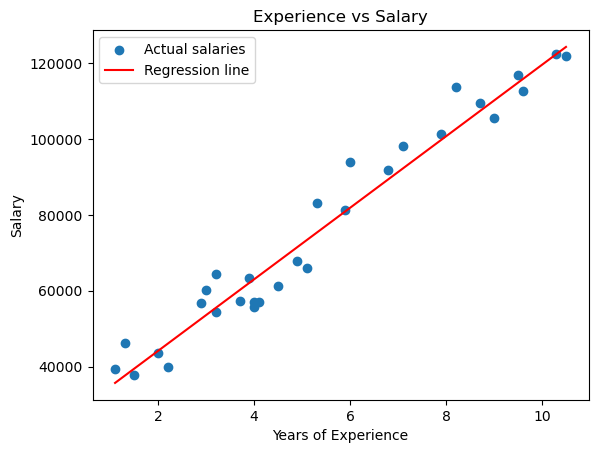

In [7]:
plt.scatter(X["YearsExperience"], y, label="Actual salaries")
plt.plot(X["YearsExperience"], model.predict(X),
         color="red", label="Regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary")
plt.legend()
plt.show()